# Solar irradiation and China's solar PV exports
Panels, Cells and Wafers combined, 2022–2025.

**Question.** Is annual solar irradiation associated with recorded PV export capacity after considering population, real GDP per capita, prior-year installed PV, region and year?

This analysis supports market comparisons for PV exporters. It uses the same regression specifications as the Panels-only notebook, with a newly aggregated three-product outcome and rebuilt sample.

## Data and observation unit
Each row is one destination country/economy in one year. We sum the source `Capacity (MW)` for **Panels, Cells and Wafers**. Figures divide this total by 1,000 to show **GW-equivalent**. This is a sum of product-stage capacity equivalents. It can include related upstream and downstream shipments and does not measure unique installed capacity or final demand.

The main sample requires at least one selected-product record in each of the 12 months, complete explanatory data, and positive logged variables. **It does not require all three products in every month.** We retain the number of recorded months for each product. Missing shipment records are not filled with zero; totals cover recorded shipments.

- **Exports:** `data/Raw/mart_solar_exports_full_release_monthly.csv`, retaining country/economy records in 2022–2025.
- **Radiation:** `data/Processed/solar_radiation_country_year.csv`. NASA POWER annual GHI is averaged over country land area, in kWh/m²/year. These are actual annual values for 2022–2025.
- **Geography and controls:** `data/Processed/solar_radiation_country_year_2022_2025.csv`. We reuse only country mapping, population, real GDP per capita and previous-year installed PV. Its old outcome, radiation and sample flags are ignored.

Population and real GDP per capita are from the World Bank. Prior-year installed PV is from IRENA: 2021 capacity is paired with 2022 exports, and so on.

In [1]:
%matplotlib inline
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import statsmodels.formula.api as smf
from IPython.display import display, Markdown

# Run from the repository root or the Scripts folder.
root = Path.cwd()
if not (root / 'data').exists():
    root = root.parent
output = root / 'Results/Solar_Radiation_All_Products'
output.mkdir(parents=True, exist_ok=True)

raw = pd.read_csv(root / 'data/Raw/mart_solar_exports_full_release_monthly.csv',
                  parse_dates=['Date'])
exports = raw[(raw['Commodity type'].isin(['Panels', 'Cells', 'Wafers'])) &
              (raw['Area type'] == 'Country or economy') &
              raw['Date'].dt.year.between(2022, 2025)].copy()
exports['export_year'] = exports['Date'].dt.year
exports['reporting_month'] = exports['Date'].dt.to_period('M')
assert not exports.duplicated(['Area', 'reporting_month', 'Commodity type']).any()
assert exports['Capacity (MW)'].notna().all()
assert exports['Capacity (MW)'].ge(0).all()

# Sum recorded product capacities; exclude supplied regional/global totals.
annual = exports.groupby(['Area', 'export_year'], as_index=False).agg(
    annual_export_capacity_mw=('Capacity (MW)', 'sum'),
    months_present=('reporting_month', 'nunique'))

# Zero here means zero recorded months, not an imputed shipment quantity.
counts = exports.groupby(['Area', 'export_year', 'Commodity type'])[
    'reporting_month'].nunique().unstack().fillna(0).astype(int)
counts = counts.rename(columns={'Panels': 'panels_months',
                                 'Cells': 'cells_months', 'Wafers': 'wafers_months'})
annual = annual.merge(counts.reset_index(), on=['Area', 'export_year'],
                      validate='one_to_one')
annual = annual.rename(columns={'Area': 'ember_destination'})

controls = pd.read_csv(root / 'data/Processed/solar_radiation_country_year_2022_2025.csv')
controls = controls[['ember_destination', 'export_year', 'iso3', 'figure3_region',
                     'population', 'real_gdp_pc_2015_usd', 'pv_capacity_year',
                     'lag_pv_capacity_mw']]
annual = annual.merge(controls, on=['ember_destination', 'export_year'],
                      how='left', validate='one_to_one')
radiation = pd.read_csv(root / 'data/Processed/solar_radiation_country_year.csv')
annual = annual.merge(radiation[['iso3', 'export_year', 'ghi_kwh_m2_year']],
                      on=['iso3', 'export_year'], how='left', validate='many_to_one')

required = ['annual_export_capacity_mw', 'population', 'real_gdp_pc_2015_usd',
            'lag_pv_capacity_mw', 'ghi_kwh_m2_year']
keep = ((annual['months_present'] == 12) & annual[required].gt(0).all(axis=1) &
        annual['iso3'].notna() & annual['figure3_region'].notna())
sample = annual[keep].copy()

month_counts = exports.groupby('Area')['reporting_month'].nunique()
complete_names = month_counts[month_counts == 48].index
sample['complete_48_months'] = sample['ember_destination'].isin(complete_names)
assert not sample.duplicated(['iso3', 'export_year']).any()
assert sample['pv_capacity_year'].eq(sample['export_year'] - 1).all()
assert np.isfinite(sample[required]).all().all()

sample['capacity_gw'] = sample['annual_export_capacity_mw'] / 1000
sample['log_capacity'] = np.log(sample['annual_export_capacity_mw'])
sample['log_population'] = np.log(sample['population'])
sample['log_gdp_pc'] = np.log(sample['real_gdp_pc_2015_usd'])
sample['log_lag_pv'] = np.log(sample['lag_pv_capacity_mw'])
sample['ghi_per_100'] = sample['ghi_kwh_m2_year'] / 100
sample.to_csv(root / 'data/Processed/solar_radiation_all_products_sample.csv', index=False)

print(f'Selected export rows: {len(exports):,}; annual records before filtering: {len(annual)}.')
print(f"Main sample: {len(sample)} country-years, {sample['iso3'].nunique()} destinations.")
print('Country-years with 12 recorded months for each product:')
print(sample[['panels_months', 'cells_months', 'wafers_months']].eq(12).sum().to_string())
summary = sample.groupby('export_year').agg(
    Destinations=('iso3', 'nunique'), Export_GW_equivalent=('capacity_gw', 'sum'))
display(Markdown('**Annual summary of the regression sample.** Totals cover the destinations retained in each year.'))
display(summary.round(2))

Selected export rows: 15,924; annual records before filtering: 866.
Main sample: 540 country-years, 155 destinations.
Country-years with 12 recorded months for each product:
panels_months    526
cells_months     230
wafers_months     77


**Annual summary of the regression sample.** Totals cover the destinations retained in each year.

,Destinations,Export_GW_equivalent
export_year,,
2022,121,211.61
2023,136,312.08
2024,142,349.44
2025,141,420.38


## Figure A. Annual radiation–export comparison
**Question.** How do recorded exports vary with irradiation in each year?

Each point is a destination-year in the regression sample. The x-axis shows annual irradiation in **kWh/m²/year**. The y-axis shows combined Panels, Cells and Wafers exports in **GW-equivalent**, on a logarithmic scale. Colors indicate regions. The two largest destinations in each year are labelled.

Black lines describe the unadjusted relationship separately by year. They do not include the market controls used in the main regression. Similar irradiation can correspond to very different recorded exports.

Figure B shows the relationship after accounting for the main-model controls.

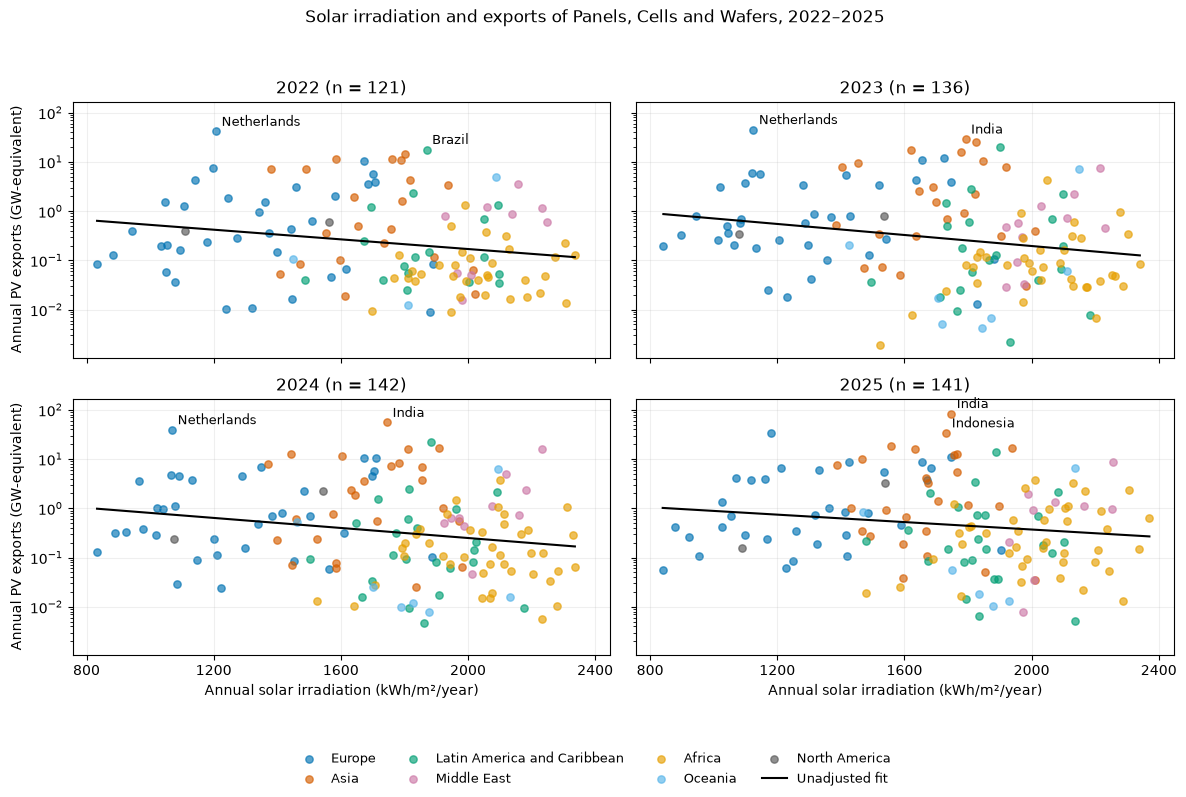

Unadjusted fitted slopes are negative in 4 of 4 years.


In [2]:
colors = {
    'Europe': '#0072B2', 'Asia': '#D55E00',
    'Latin America and Caribbean': '#009E73', 'Middle East': '#CC79A7',
    'Africa': '#E69F00', 'Oceania': '#56B4E9', 'North America': '#555555'
}
fig, axes = plt.subplots(2, 2, figsize=(12, 8), sharex=True, sharey=True)
yearly_slopes = []
for ax, year in zip(axes.flat, [2022, 2023, 2024, 2025]):
    d = sample[sample['export_year'] == year]
    for region, color in colors.items():
        r = d[d['figure3_region'] == region]
        ax.scatter(r['ghi_kwh_m2_year'], r['capacity_gw'], color=color,
                   label=region, s=28, alpha=0.65)

    slope, intercept = np.polyfit(d['ghi_kwh_m2_year'], np.log(d['capacity_gw']), 1)
    yearly_slopes.append(slope)
    x = np.linspace(d['ghi_kwh_m2_year'].min(), d['ghi_kwh_m2_year'].max(), 100)
    ax.plot(x, np.exp(intercept + slope * x), color='black', label='Unadjusted fit')

    for _, row in d.nlargest(2, 'capacity_gw').iterrows():
        ax.annotate(row['ember_destination'],
                    (row['ghi_kwh_m2_year'], row['capacity_gw']),
                    xytext=(4, 4), textcoords='offset points', fontsize=9)
    ax.set_title(f'{year} (n = {len(d)})')
    ax.set_yscale('log')
    ax.set_ylim(sample['capacity_gw'].min() / 1.8, sample['capacity_gw'].max() * 2)
    ax.set_xticks([800, 1200, 1600, 2000, 2400])
    ax.grid(alpha=0.2)

for ax in axes[:, 0]:
    ax.set_ylabel('Annual PV exports (GW-equivalent)')
for ax in axes[1, :]:
    ax.set_xlabel('Annual solar irradiation (kWh/m²/year)')
handles, labels = axes[0, 0].get_legend_handles_labels()
fig.legend(handles, labels, loc='lower center', ncol=4, frameon=False, fontsize=9)
fig.suptitle('Solar irradiation and exports of Panels, Cells and Wafers, 2022–2025')
fig.tight_layout(rect=[0, 0.10, 1, 0.95])
fig.savefig(output / 'solar_radiation_all_products_2022_2025.png',
            dpi=200, bbox_inches='tight')
plt.show()
print(f'Unadjusted fitted slopes are negative in {sum(s < 0 for s in yearly_slopes)} of 4 years.')

Sources: Ember China Solar Exports, NASA POWER and the project's country-region mapping. Product mix and incomplete product-specific coverage limit interpretation of the combined outcome.

## Regression method and hypothesis
We regress **ln(annual combined export capacity in MW)** on irradiation, considering population, real GDP per capita, prior-year installed PV capacity, region and year. Population, income and installed PV are also logged. Radiation is scaled per **100 kWh/m²/year**.

- **H₀:** The adjusted irradiation coefficient is zero, **β = 0**.
- **H₁:** The adjusted irradiation coefficient differs from zero, **β ≠ 0**.

We use country-clustered standard errors, finite-sample corrections, Student-t inference and a **5% significance level**. The first three models use the same country-year sample.

In [3]:
year_model = smf.ols('log_capacity ~ ghi_per_100 + C(export_year)', data=sample).fit(
    cov_type='cluster', cov_kwds={'groups': sample['iso3']}, use_t=True)

formula = ('log_capacity ~ ghi_per_100 + log_population + log_gdp_pc + '
           'log_lag_pv + C(figure3_region) + C(export_year)')
main_model = smf.ols(formula, data=sample).fit(
    cov_type='cluster', cov_kwds={'groups': sample['iso3']}, use_t=True)

country_formula = formula.replace('C(figure3_region)', 'C(iso3)')
country_model = smf.ols(country_formula, data=sample).fit(
    cov_type='cluster', cov_kwds={'groups': sample['iso3']}, use_t=True)

balanced = sample[sample['complete_48_months']].copy()
balanced_model = smf.ols(formula, data=balanced).fit(
    cov_type='cluster', cov_kwds={'groups': balanced['iso3']}, use_t=True)

models = {'Year adjusted': year_model, 'Main model': main_model,
          'Country + year effects': country_model,
          '48-month destinations': balanced_model}
rows = []
for name, model in models.items():
    lower, upper = model.conf_int().loc['ghi_per_100']
    data = balanced if name == '48-month destinations' else sample
    rows.append({'Model': name, 'N': int(model.nobs),
                 'Destinations': data['iso3'].nunique(),
                 'GHI coefficient': model.params['ghi_per_100'],
                 'Cluster SE': model.bse['ghi_per_100'],
                 'CI lower': lower, 'CI upper': upper,
                 '95% CI': f'[{lower:.4f}, {upper:.4f}]',
                 'p value': model.pvalues['ghi_per_100'],
                 'R squared': model.rsquared})
results = pd.DataFrame(rows)
columns = ['Model', 'N', 'Destinations', 'GHI coefficient', 'Cluster SE',
           '95% CI', 'p value', 'R squared']
display(results[columns].style.hide(axis='index').format(precision=4))

Model,N,Destinations,GHI coefficient,Cluster SE,95% CI,p value,R squared
Year adjusted,540,155,-0.1119,0.0390,"[-0.1890, -0.0348]",0.0047,0.0512
Main model,540,155,0.1036,0.0421,"[0.0203, 0.1868]",0.0151,0.6897
Country + year effects,540,155,-0.0210,0.1202,"[-0.2585, 0.2166]",0.8618,0.9325
48-month destinations,445,112,0.1193,0.0481,"[0.0241, 0.2146]",0.0145,0.6840


**Table notes.** N counts country-years. Confidence intervals are country-clustered 95% intervals. The coefficient is per additional 100 kWh/m²/year.

- **Year adjusted:** irradiation and year indicators.
- **Main model:** adds population, real GDP per capita, prior-year installed PV and region indicators.
- **Country + year effects:** replaces region indicators with country indicators, keeping the other controls. This focuses on annual changes within countries.
- **48-month destinations:** repeats the main model for destinations with selected-product records in every month of 2022–2025. The combined outcome stays the same. This coverage rule does not establish complete reporting for each separate product.

## Figure B. Relationship after accounting for other factors
**Question.** How is irradiation associated with combined PV exports after considering population, real GDP per capita, previous-year installed PV, region and year?

This partial regression plot uses the **same main-model sample and controls**. Both axes show deviations after accounting for the other factors. The x-axis is adjusted irradiation in **100 kWh/m²/year**. The y-axis is adjusted **ln(annual combined export capacity in MW)**. Negative values represent below-predicted values, not negative sunlight or shipments.

The fitted line uses the main model's irradiation coefficient. The displayed confidence interval and p-value also come from that model, with country-clustered inference.

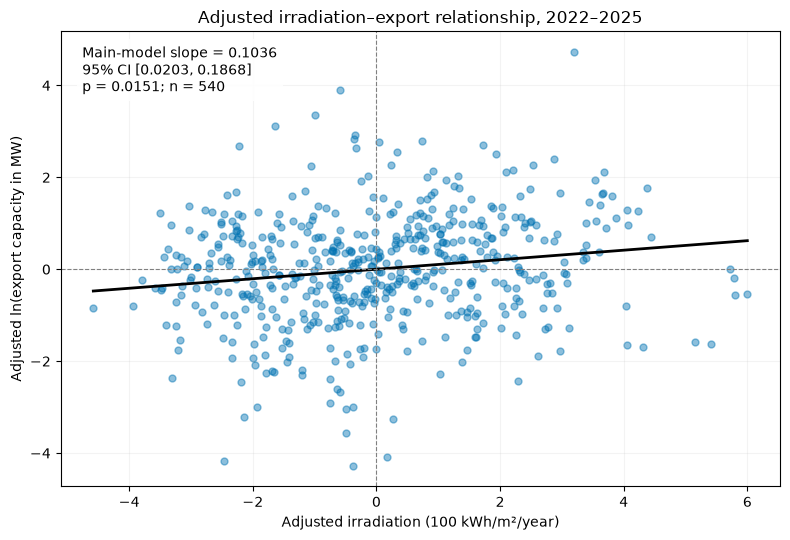

In [4]:
# Remove the same control variables from each axis for visualization.
other_factors = ('log_population + log_gdp_pc + log_lag_pv + '
                 'C(figure3_region) + C(export_year)')
radiation_resid = smf.ols('ghi_per_100 ~ ' + other_factors, data=sample).fit().resid
export_resid = smf.ols('log_capacity ~ ' + other_factors, data=sample).fit().resid

# Use the existing main-model coefficient and country-clustered inference.
adjusted_beta = main_model.params['ghi_per_100']
adjusted_lower, adjusted_upper = main_model.conf_int().loc['ghi_per_100']
adjusted_p = main_model.pvalues['ghi_per_100']

fig, ax = plt.subplots(figsize=(8, 5.5))
ax.scatter(radiation_resid, export_resid, s=25, alpha=0.45, color='#0072B2')
x_line = np.linspace(radiation_resid.min(), radiation_resid.max(), 100)
ax.plot(x_line, adjusted_beta * x_line, color='black', linewidth=2)
ax.axhline(0, color='gray', linestyle='--', linewidth=0.8)
ax.axvline(0, color='gray', linestyle='--', linewidth=0.8)
ax.set_xlabel('Adjusted irradiation (100 kWh/m²/year)')
ax.set_ylabel('Adjusted ln(export capacity in MW)')
ax.set_title('Adjusted irradiation–export relationship, 2022–2025')
ax.text(0.03, 0.97,
        f'Main-model slope = {adjusted_beta:.4f}\n'
        f'95% CI [{adjusted_lower:.4f}, {adjusted_upper:.4f}]\n'
        f'p = {adjusted_p:.4f}; n = {len(sample)}',
        transform=ax.transAxes, va='top', fontsize=10,
        bbox={'facecolor': 'white', 'edgecolor': 'none', 'alpha': 0.9})
ax.grid(alpha=0.15)
fig.tight_layout()
fig.savefig(output / 'solar_radiation_all_products_adjusted.png',
            dpi=200, bbox_inches='tight')
plt.show()

**Interpretation and limitation.** The upward line displays the positive irradiation coefficient from the main regression. The downward lines in Figure A describe the unadjusted comparisons. Figure B accounts for the specified market characteristics, region and year, so it displays a different comparison. Points still vary widely around the line. This is a visualization of the existing model, not evidence of causation or a prediction of actual GW shipments.

The outcome continues to combine Panels, Cells and Wafers. Sources: Ember China Solar Exports, NASA POWER, World Bank and IRENASTAT.

In [5]:
beta = main_model.params['ghi_per_100']
lower, upper = main_model.conf_int().loc['ghi_per_100']
effect = 100 * np.expm1(beta)
effect_lower, effect_upper = 100 * np.expm1([lower, upper])
main_test = ('statistically significant at 5%' if main_model.pvalues['ghi_per_100'] < 0.05
             else 'not statistically significant at 5%')
coverage_test = ('remains statistically significant at 5%' if
                 balanced_model.pvalues['ghi_per_100'] < 0.05 else
                 'is not statistically significant at 5%')
country_test = ('is statistically significant at 5%' if
                country_model.pvalues['ghi_per_100'] < 0.05 else
                'is not statistically significant at 5%')

display(Markdown(f'''
### Finding 1. Adjusted association
In **{len(sample)} country-years from {sample['iso3'].nunique()} destinations**, the main irradiation coefficient is **{beta:.4f}** and is **{main_test}** (p = **{main_model.pvalues['ghi_per_100']:.4f}**). An additional 100 kWh/m²/year is associated with an estimated **{effect:+.1f}% difference** in combined recorded export capacity on the model's geometric scale (95% interval: **{effect_lower:+.1f}% to {effect_upper:+.1f}%**), conditional on the other factors.

### Finding 2. Cross-country and within-country results differ
The year-adjusted coefficient is **{year_model.params['ghi_per_100']:.4f}**. For 48-month destinations, the main-model estimate is **{balanced_model.params['ghi_per_100']:.4f}** (N = **{int(balanced_model.nobs)}**, p = **{balanced_model.pvalues['ghi_per_100']:.4f}**) and **{coverage_test}**. The country-and-year-effects estimate is **{country_model.params['ghi_per_100']:.4f}** (p = **{country_model.pvalues['ghi_per_100']:.4f}**) and **{country_test}**. This specification examines a different question: annual changes within the same country.

**Interpretation.** Irradiation alone is insufficient to explain destination patterns. Consider market characteristics and the production stage of the imported equipment. These are associations, not causal effects or profit forecasts. A non-significant estimate does not establish no relationship, and different significance levels alone do not establish that coefficients differ.
'''))


### Finding 1. Adjusted association
In **540 country-years from 155 destinations**, the main irradiation coefficient is **0.1036** and is **statistically significant at 5%** (p = **0.0151**). An additional 100 kWh/m²/year is associated with an estimated **+10.9% difference** in combined recorded export capacity on the model's geometric scale (95% interval: **+2.1% to +20.5%**), conditional on the other factors.

### Finding 2. Cross-country and within-country results differ
The year-adjusted coefficient is **-0.1119**. For 48-month destinations, the main-model estimate is **0.1193** (N = **445**, p = **0.0145**) and **remains statistically significant at 5%**. The country-and-year-effects estimate is **-0.0210** (p = **0.8618**) and **is not statistically significant at 5%**. This specification examines a different question: annual changes within the same country.

**Interpretation.** Irradiation alone is insufficient to explain destination patterns. Consider market characteristics and the production stage of the imported equipment. These are associations, not causal effects or profit forecasts. A non-significant estimate does not establish no relationship, and different significance levels alone do not establish that coefficients differ.


## Figure C. Model comparison and diagnostic
The left panel compares irradiation coefficients per **100 kWh/m²/year**, with country-clustered 95% intervals. The right panel compares main-model residuals with fitted values, both in log-capacity units. Residuals are observed minus fitted log capacity.

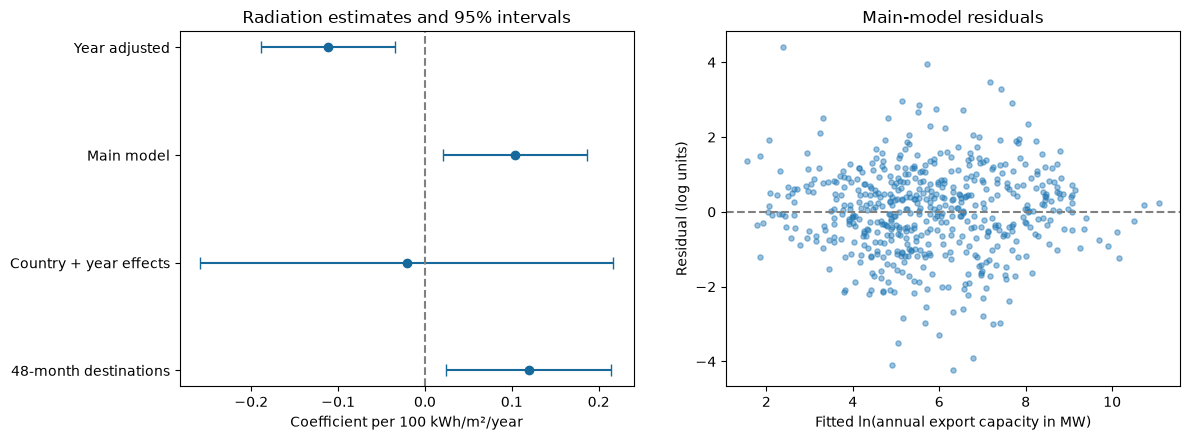

Saved: 3 PNG figures in Results/Solar_Radiation_All_Products/
Saved: data/Processed/solar_radiation_all_products_sample.csv


In [6]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
positions = np.arange(len(results))
axes[0].errorbar(results['GHI coefficient'], positions,
    xerr=[results['GHI coefficient'] - results['CI lower'],
          results['CI upper'] - results['GHI coefficient']],
    fmt='o', capsize=4, color='#17699c')
axes[0].axvline(0, color='gray', linestyle='--')
axes[0].set_yticks(positions, results['Model'])
axes[0].invert_yaxis()
axes[0].set_xlabel('Coefficient per 100 kWh/m²/year')
axes[0].set_title('Radiation estimates and 95% intervals')

axes[1].scatter(main_model.fittedvalues, main_model.resid, s=14, alpha=0.45)
axes[1].axhline(0, color='gray', linestyle='--')
axes[1].set_xlabel('Fitted ln(annual export capacity in MW)')
axes[1].set_ylabel('Residual (log units)')
axes[1].set_title('Main-model residuals')
fig.tight_layout(w_pad=3)
fig.savefig(output / 'solar_radiation_all_products_diagnostic.png',
            dpi=200, bbox_inches='tight')
plt.show()
print('Saved: 3 PNG figures in Results/Solar_Radiation_All_Products/')
print('Saved: data/Processed/solar_radiation_all_products_sample.csv')

**Diagnostic limitation.** The residual plot helps identify curvature, changing error spread and unusual observations. It is a visual check, not a pass/fail test. Country-clustered inference allows unequal variances and dependence within a destination under the model's assumptions. It does not fix omitted variables, measurement errors or the functional form.

## Limitations
- **Combined products:** Cells and Wafers are upstream inputs. Their destinations may reflect manufacturing supply chains rather than local panel-installation demand. Summed stage equivalents should not be interpreted as unique installed PV capacity.
- **Coverage:** Twelve combined months do not mean twelve months for each product. Counts in the saved sample make this distinction visible. Missing records are not assumed to be zero trade.
- **Measurement:** Capacity is estimated by Ember. Country-average irradiation at 1° resolution may not represent the locations of PV projects. Customs destinations can differ from final installation markets because of re-exports.
- **Interpretation:** The model is conditional on income, population and the existing installed base. It does not measure every pathway connecting solar resources to trade. Four years provide limited within-country variation. Policy, manufacturing, tariffs and logistics remain relevant.

## Run and export
Open this notebook from the repository root or the `Scripts` folder in VS Code. Select a Python kernel with `pandas`, `numpy`, `matplotlib`, `statsmodels` and `IPython`, then **Run All**. This recreates the three PNGs and the one processed sample CSV.

After running, save the notebook. To regenerate the HTML from saved outputs, run from the repository root:

```bash
python3 -m nbconvert --to html --no-input --embed-images Scripts/Solar_Radiation_All_Products.ipynb --output-dir Docs
```

**Sources:** [Ember China Solar Exports](https://ember-energy.org/data/china-solar-exports-data/), [NASA POWER](https://power.larc.nasa.gov/docs/services/aws/), [World Bank population](https://data.worldbank.org/indicator/SP.POP.TOTL), [World Bank real GDP per capita](https://data.worldbank.org/indicator/NY.GDP.PCAP.KD), and [IRENASTAT](https://pxweb.irena.org/pxweb/en/IRENASTAT/).